In [1]:
%cd ..
%load_ext autoreload
%autoreload 2

/home/dongmin/userdata/dongmin/omr-data-preprocessing


/home/dongmin/userdata/dongmin/omr-data-preprocessing/.venv/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
from pathlib import Path

import math
import random

import json
import csv
import strictyaml as syaml

from tqdm import tqdm
import matplotlib.pyplot as plt

import cv2
import numpy as np

from omrdp.utils.musescore import convert_linearized_musicxml_to_image

In [3]:
prj_dir = Path.cwd()

In [4]:
mss_path = prj_dir / 'single-system.mss'
mss_path.exists()

True

## LMX Rendering

### Load Examples

In [5]:
gt_lmxe_path = prj_dir / 'temp' / 'gt_scanned_sq7302602_0010_0003.lmxe'
pred_lmxe_path = prj_dir / 'temp' / 'pred_scanned_sq7302602_0010_0003.lmxe'

gt_lmxe_path.exists(), pred_lmxe_path.exists()

(True, True)

['mscore', '-S', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/single-system.mss', '--force', '-o', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/gt_scanned_sq7302602_0010_0003.mscx', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/gt_scanned_sq7302602_0010_0003.musicxml']
['mscore', '-r', '300', '--force', '-o', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/gt_scanned_sq7302602_0010_0003.png', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/gt_scanned_sq7302602_0010_0003.mscx']


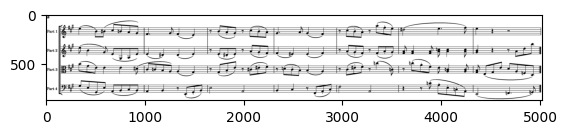

In [16]:
tgt_path = rendered_path = convert_linearized_musicxml_to_image(
  gt_lmxe_path,
  prj_dir / 'temp' / f'{gt_lmxe_path.stem}.png',
  style_path=mss_path,
  dpi=300,
)

plt.imshow(cv2.imread(tgt_path))

['mscore', '-S', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/single-system.mss', '--force', '-o', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/pred_scanned_sq7302602_0010_0003.mscx', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/pred_scanned_sq7302602_0010_0003.musicxml']
['mscore', '-r', '300', '--force', '-o', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/pred_scanned_sq7302602_0010_0003.png', '/home/dongmin/userdata/dongmin/omr-data-preprocessing/temp/pred_scanned_sq7302602_0010_0003.mscx']


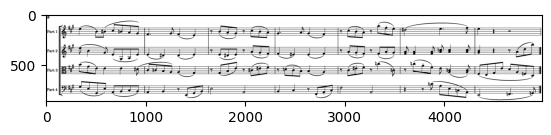

In [17]:
tgt_path = convert_linearized_musicxml_to_image(
  pred_lmxe_path,
  prj_dir / 'temp' / f'{pred_lmxe_path.stem}.png',
  style_path=mss_path,
  dpi=300,
)

plt.imshow(cv2.imread(tgt_path))